1.setup and load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
print(df.shape)
df.info()

(20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


2. Explore the data and check the missing values

In [4]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [5]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

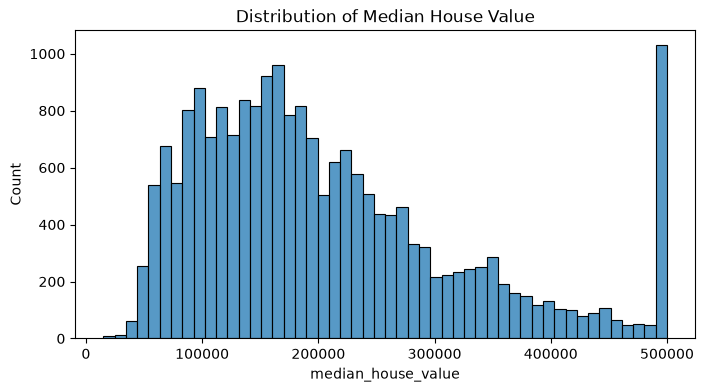

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(df["median_house_value"], bins=50)
plt.title("Distribution of Median House Value")
plt.show()

histogram shows the right skew with the spike at 500,000 which is the cap

3. Correlation heatmap

Correlation matrix(just numbers). Muticollineraity comes into play here

In [8]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()
corr

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


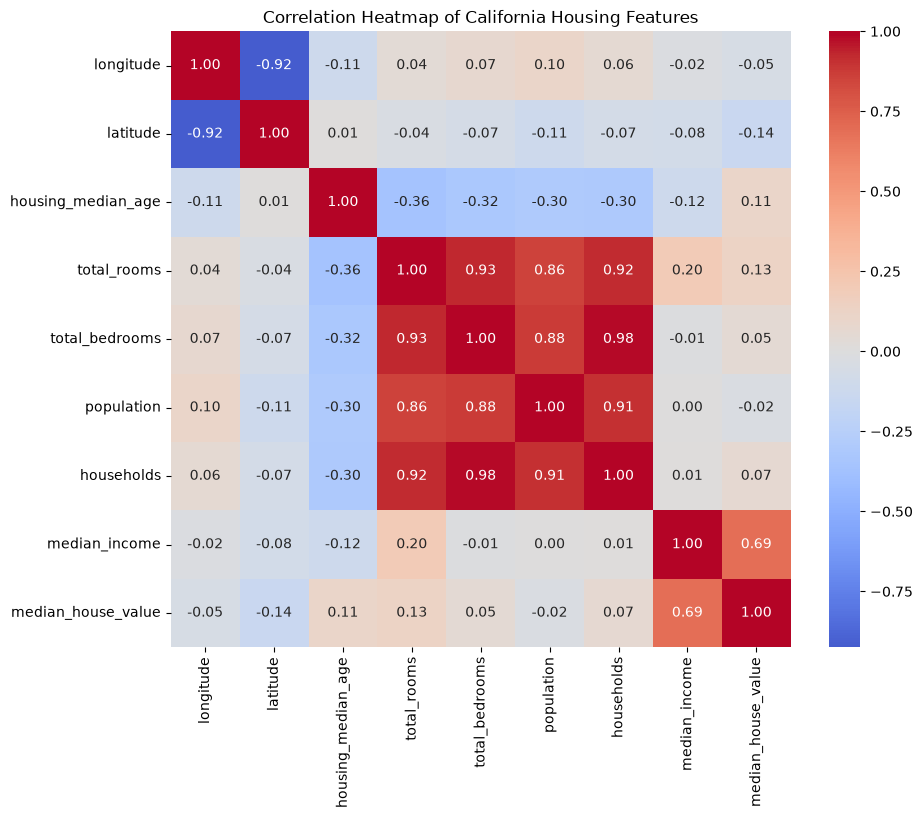

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of California Housing Features")
plt.show()

In [10]:
corr["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

-median_income has the strongest correlation with median_house_value(approximately 0.69), income is the main driver of price

-total_rooms, total_bedrooms, population and households are very strongly correlated with each other (many values above 0.85, with total_bedrooms and households around 0.98). This is the multicollinearity.

-longitude and latitude are strongly negatively correlated with each other (about -0.92), which makes sense because California runs diagonally

4.Engineer features and encode ocean_proximity

In [11]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# a true interaction feature (two features multiplied)
df["income_x_rooms_per_hh"] = df["median_income"] * df["rooms_per_household"]

total_rooms, total_bedrooms... depends on how big a district is that is what makes them so correlated with each other

In [12]:
df = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True, dtype=int)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms_per_hh,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,6.984127,0.146591,2.555556,58.144254,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,6.238137,0.155797,2.109842,51.785271,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,8.288136,0.129516,2.802260,60.150315,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,5.817352,0.184458,2.547945,32.827897,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,6.281853,0.172096,2.181467,24.161264,0,0,1,0


drop_first=True drops one category (<1H OCEAN) and treats it as the baseline. This matters for OLS: keeping all five dummy columns would make them perfectly collinear.


In [13]:
print(df.shape)
df.isnull().sum()

(20640, 17)


longitude                       0
latitude                        0
housing_median_age              0
total_rooms                     0
total_bedrooms                207
population                      0
households                      0
median_income                   0
median_house_value              0
rooms_per_household             0
bedrooms_per_room             207
population_per_household        0
income_x_rooms_per_hh           0
ocean_proximity_INLAND          0
ocean_proximity_ISLAND          0
ocean_proximity_NEAR BAY        0
ocean_proximity_NEAR OCEAN      0
dtype: int64

total_bedrooms has 207 missing, and so does bedrooms_per_room (it inherits the gaps). Everything else is 0.
New columns are ocean_proximity_INLAND, ocean_proximity_ISLAND, ocean_proximity_NEAR BAY, ocean_proximity_NEAR OCEAN.

5. Split, impute, standadize

In [14]:
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(16512, 16) (4128, 16)


In [15]:
imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test), columns=X_test.columns, index=X_test.index
)

print(X_train_imp.isnull().sum().sum(), X_test_imp.isnull().sum().sum())

0 0


the median is used because these columns are skewed, and the median isn’t pulled around by extreme districts the way the mean is.the pattern: fit_transform on train, only transform on test.

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

[ 0.  0. -0.  0. -0.  0. -0. -0.  0. -0.  0.  0. -0. -0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


6. Fit OLS, then Ridge and Lasso with GridSearchCV

In [17]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    return {
        "Model": name,
        "Train RMSE": np.sqrt(mean_squared_error(y_tr, pred_tr)),
        "Test RMSE": np.sqrt(mean_squared_error(y_te, pred_te)),
        "Test MAE": mean_absolute_error(y_te, pred_te),
        "Train R2": r2_score(y_tr, pred_tr),
        "Test R2": r2_score(y_te, pred_te),
    }

In [18]:
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[-55498.43,-55796.58, 14260.78,..., 2029.9 , -1666.18, 1146.69]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.072e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](16,)","[254.65,218.47,193. ,..., 22.19, 20.27, 13.4 ]"


In [19]:
alphas = np.logspace(-2, 4, 13)

ridge_grid = GridSearchCV(
    Ridge(),
    param_grid={"alpha": alphas},
    cv=5,
    scoring="neg_root_mean_squared_error",
)
ridge_grid.fit(X_train_scaled, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["alpha"])

Best Ridge alpha: 31.622776601683793


In [20]:
lasso_grid = GridSearchCV(
    Lasso(max_iter=20000),
    param_grid={"alpha": alphas},
    cv=5,
    scoring="neg_root_mean_squared_error",
)
lasso_grid.fit(X_train_scaled, y_train)

print("Best Lasso alpha:", lasso_grid.best_params_["alpha"])

Best Lasso alpha: 100.0


In [21]:
coef_table = pd.DataFrame({
    "Feature": X_train.columns,
    "OLS": ols.coef_,
    "Ridge": ridge_grid.best_estimator_.coef_,
    "Lasso": lasso_grid.best_estimator_.coef_,
}).round(0)
coef_table

,Feature,OLS,Ridge,Lasso
0,longitude,-55498.0,-52285.0,-52430.0
1,latitude,-55797.0,-52377.0,-52643.0
2,housing_median_age,14261.0,14266.0,14121.0
3,total_rooms,7124.0,6649.0,5859.0
4,total_bedrooms,6999.0,8687.0,7838.0
5,population,-45387.0,-44434.0,-44129.0
6,households,36349.0,34270.0,35491.0
7,median_income,92155.0,89907.0,89262.0
8,rooms_per_household,14107.0,12672.0,12299.0
9,bedrooms_per_room,18207.0,17623.0,17450.0


The coefficients that moved the most are the ones tied to the multicollinearity:
total_rooms went from 7,124 (OLS) to 5,859 (Lasso)
total_bedrooms went from 6,999 to 8,687 (Ridge)
households moved from 36,349 to 34,270 (Ridge)

Also longitude and latitude carry some of the largest coefficients (about -55,000 each), even though their raw correlation with price looked weak. They work together as a pair to locate a district.

7. Compare OLS, Ridge and Lasso

In [22]:
results = pd.DataFrame([
    evaluate("OLS", ols, X_train_scaled, y_train, X_test_scaled, y_test),
    evaluate("Ridge", ridge_grid.best_estimator_, X_train_scaled, y_train, X_test_scaled, y_test),
    evaluate("Lasso", lasso_grid.best_estimator_, X_train_scaled, y_train, X_test_scaled, y_test),
]).set_index("Model").round(3)

results

,Train RMSE,Test RMSE,Test MAE,Train R2,Test R2
Model,,,,,
OLS,67482.980,68917.317,49709.540,0.659,0.638
Ridge,67492.888,68944.757,49669.888,0.659,0.637
Lasso,67495.987,68933.826,49646.378,0.659,0.637


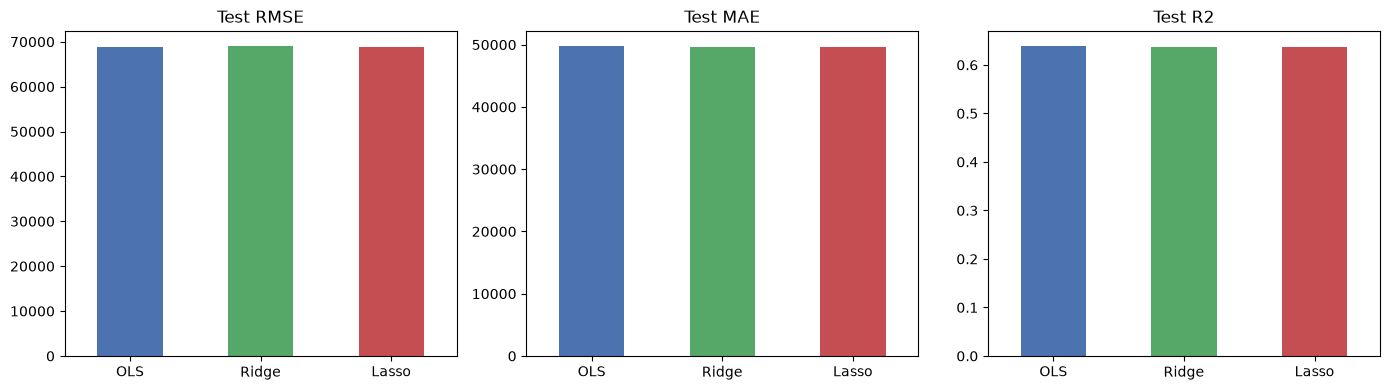

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["Test RMSE", "Test MAE", "Test R2"]):
    results[metric].plot(kind="bar", ax=ax, color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

All three models are practically identical: Test RMSE is about $68.9k, Test MAE is about $49.7k, and Test R² is 0.637 to 0.638.
OLS is marginally best on RMSE and R². Ridge and Lasso are marginally best on MAE. The differences (about $27 in RMSE) are far too small to call a real winner.
Train R² (0.659) and Test R² (0.637) are close, so there’s no overfitting. This is the useful insight: with 16 features and 16,000+ rows, the limit is the linear model itself, not variance. Regularization has little to fix, and that’s why the three models tie.

8.Predicted vs Actual, and residual plots.


In [24]:
models = {
    "OLS": ols,
    "Ridge": ridge_grid.best_estimator_,
    "Lasso": lasso_grid.best_estimator_,
}
preds = {name: m.predict(X_test_scaled) for name, m in models.items()}

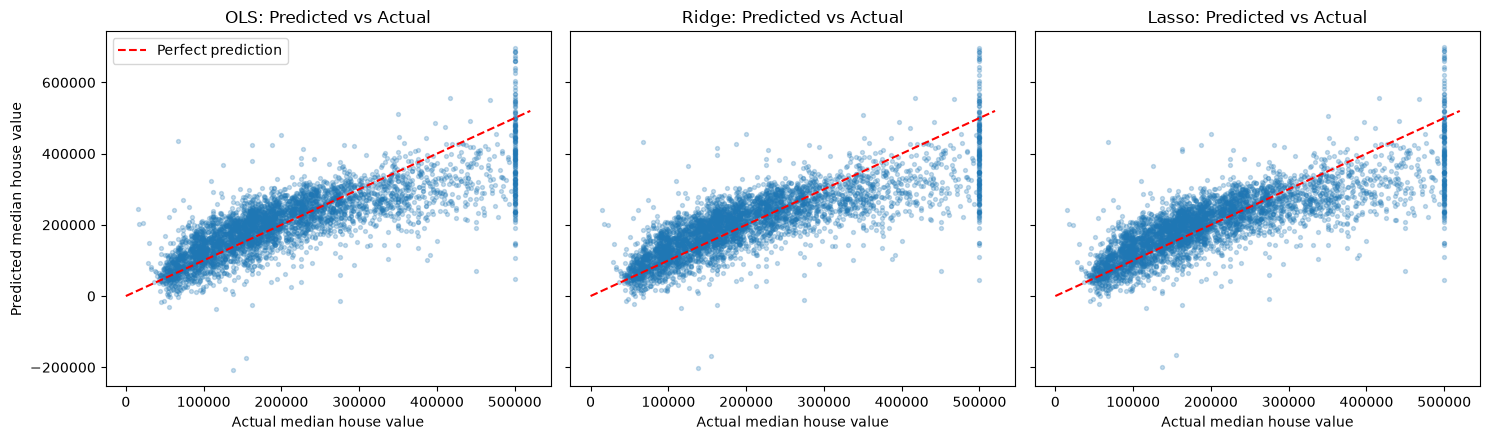

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
lims = [0, 520000]

for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.25, s=8)
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_title(f"{name}: Predicted vs Actual")
    ax.set_xlabel("Actual median house value")
axes[0].set_ylabel("Predicted median house value")
axes[0].legend()
plt.tight_layout()
plt.show()

The points follow the red line loosely, with a wide spread. The vertical stripe at 500,000 is the capped houses. Their true value was cut off, so the model predicts anything from about $50k to $700k for them. A few predictions are also negative (down to about -$200k), which is impossible for a house price and a known weakness of linear models.

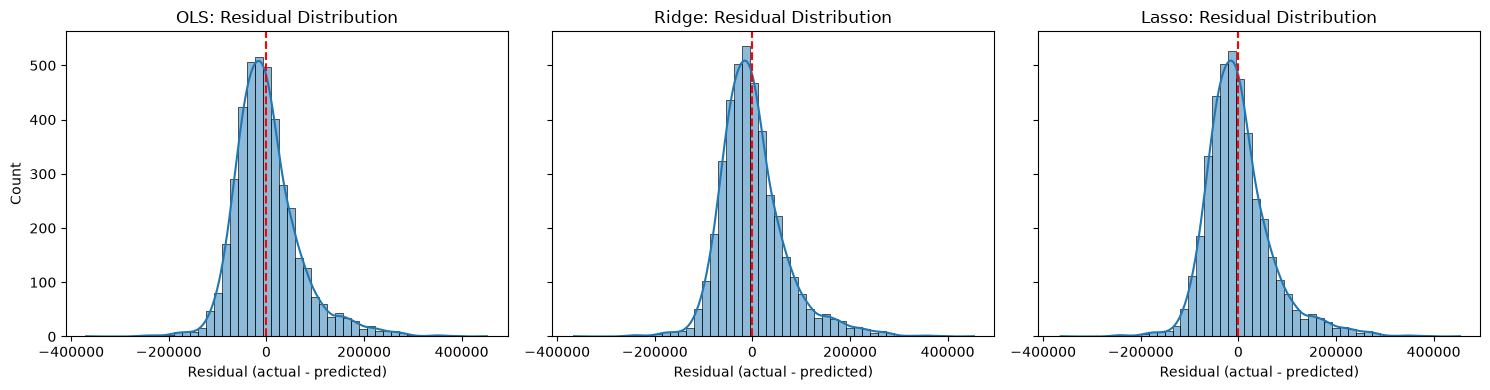

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, (name, p) in zip(axes, preds.items()):
    residuals = y_test - p
    sns.histplot(residuals, bins=50, kde=True, ax=ax)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

The residual histogram is bell-shaped and centered near zero, with a longer tail on the right. That means the model underestimates expensive houses more than it overestimates cheap ones. All three models look nearly identical, matching the metrics table

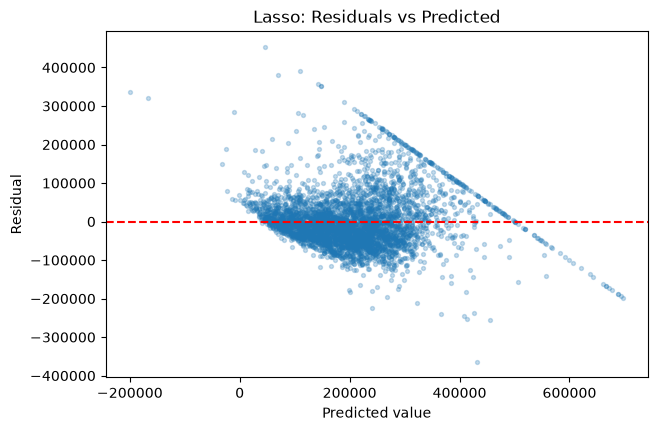

In [27]:
res = y_test - preds["Lasso"]
plt.figure(figsize=(7, 4.5))
plt.scatter(preds["Lasso"], res, alpha=0.25, s=8)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted value")
plt.ylabel("Residual")
plt.title("Lasso: Residuals vs Predicted")
plt.show()

The straight diagonal line running from the upper left to the lower right is the capped houses. Every one of them has actual = 500,001, so residual = 500,001 minus the prediction, which makes a perfect line. Also the spread grows as predicted value rises, so the model is less reliable for pricier districts.